# TA-05: Klasifikasi Tumor Payudara (Ganas vs Jinak) dengan Decision Tree
Mata Praktikum Pembelajaran Mesin, Modul 05. Lanjutan dari TP-05.

Dataset: Breast Cancer Wisconsin (Diagnostic), https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

## 1. Import Library dan Muat Data

In [1]:
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_curve, roc_auc_score)

sns.set_style("whitegrid")
df = pd.read_csv("../data/breast_cancer.csv")
print(df.shape)
df.head()

(569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Eksplorasi Data (EDA)

In [2]:
# Hapus kolom yang tidak berguna jika ada (versi Kaggle memiliki 'id' dan 'Unnamed: 32')
df = df.drop(columns=[c for c in ["id", "Unnamed: 32"] if c in df.columns])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-null

In [3]:
print("Jumlah missing value per kolom:")
print(df.isnull().sum().sum(), "nilai kosong secara total")
df.describe().T.head(12)

Jumlah missing value per kolom:
0 nilai kosong secara total


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
concave points_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
fractal dimension_mean,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


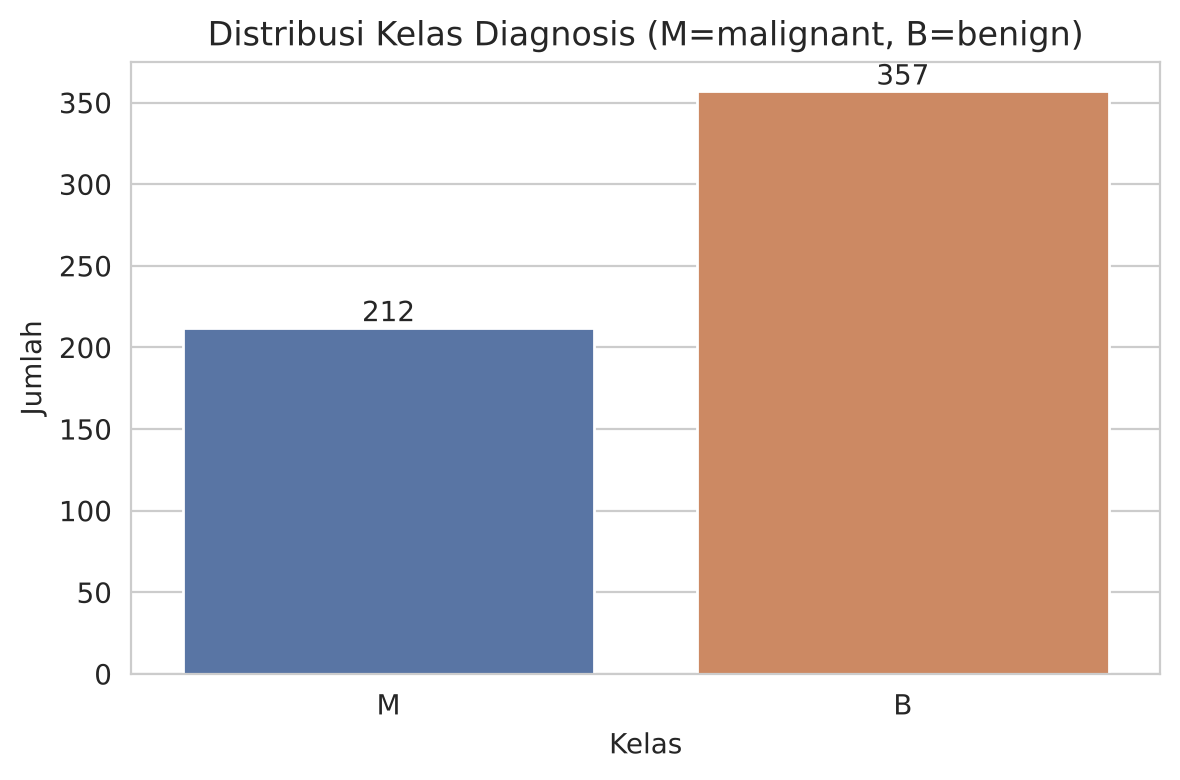

diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


In [4]:
# Distribusi target
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="diagnosis", data=df, hue="diagnosis", palette=["#4C72B0", "#DD8452"], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribusi Kelas Diagnosis (M=malignant, B=benign)")
plt.xlabel("Kelas"); plt.ylabel("Jumlah")
plt.tight_layout(); plt.savefig("../figures/01_countplot.png", dpi=150); plt.show()
print(df["diagnosis"].value_counts(normalize=True).round(3))

Untuk model dan aplikasi web, dipakai **10 fitur rata-rata (`_mean`)** agar formulir input tetap ringkas dan fitur tidak terlalu berkorelasi satu sama lain.

['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal dimension_mean']


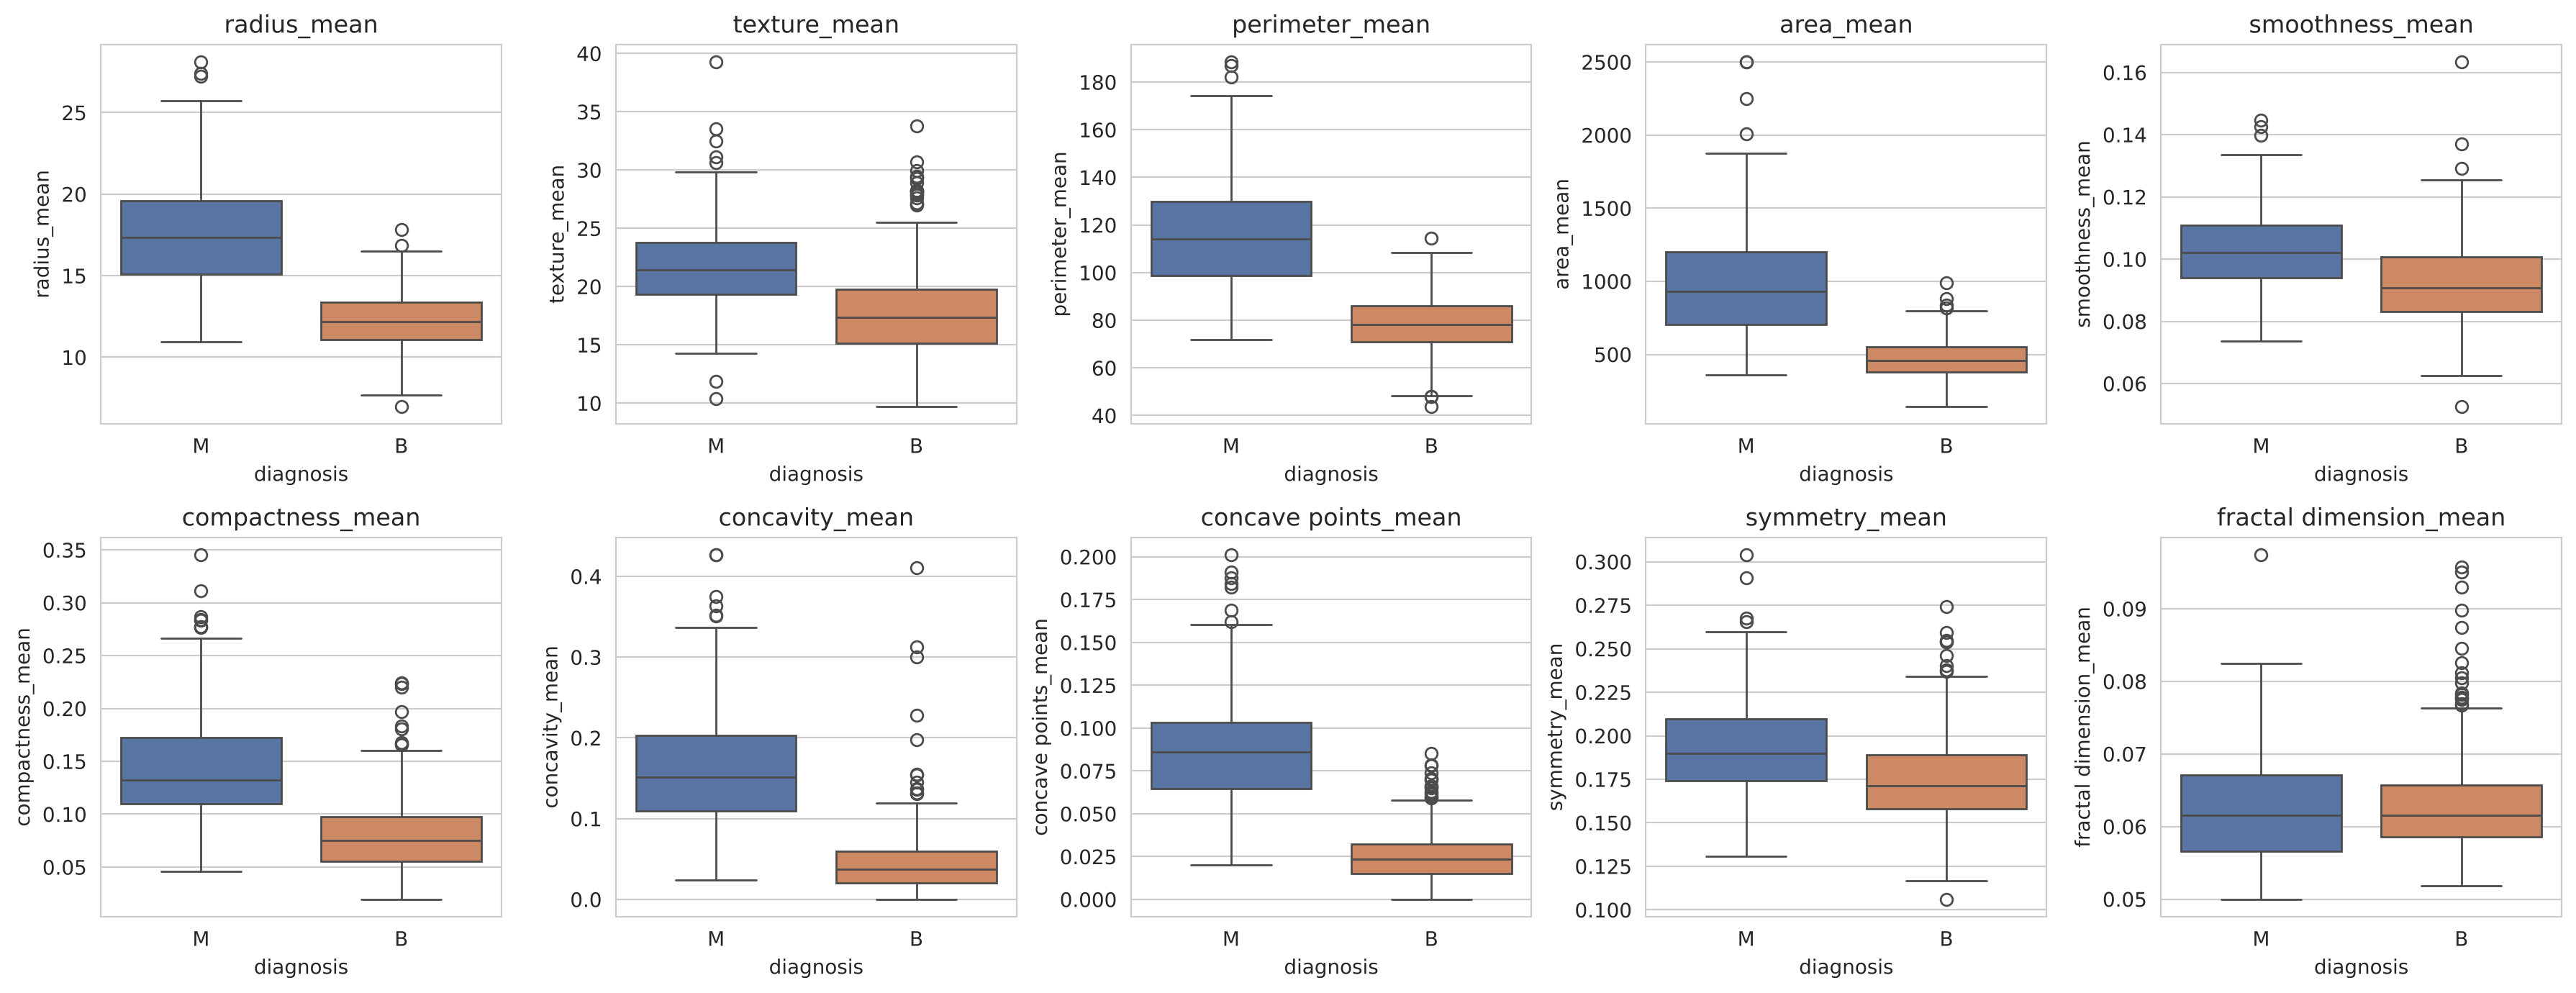

In [5]:
features = [c for c in df.columns if c.endswith("_mean")]
print(features)

# Hubungan fitur dengan target
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, f in zip(axes.ravel(), features):
    sns.boxplot(x="diagnosis", y=f, data=df, hue="diagnosis", palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.savefig("../figures/02_boxplot_fitur.png", dpi=130); plt.show()

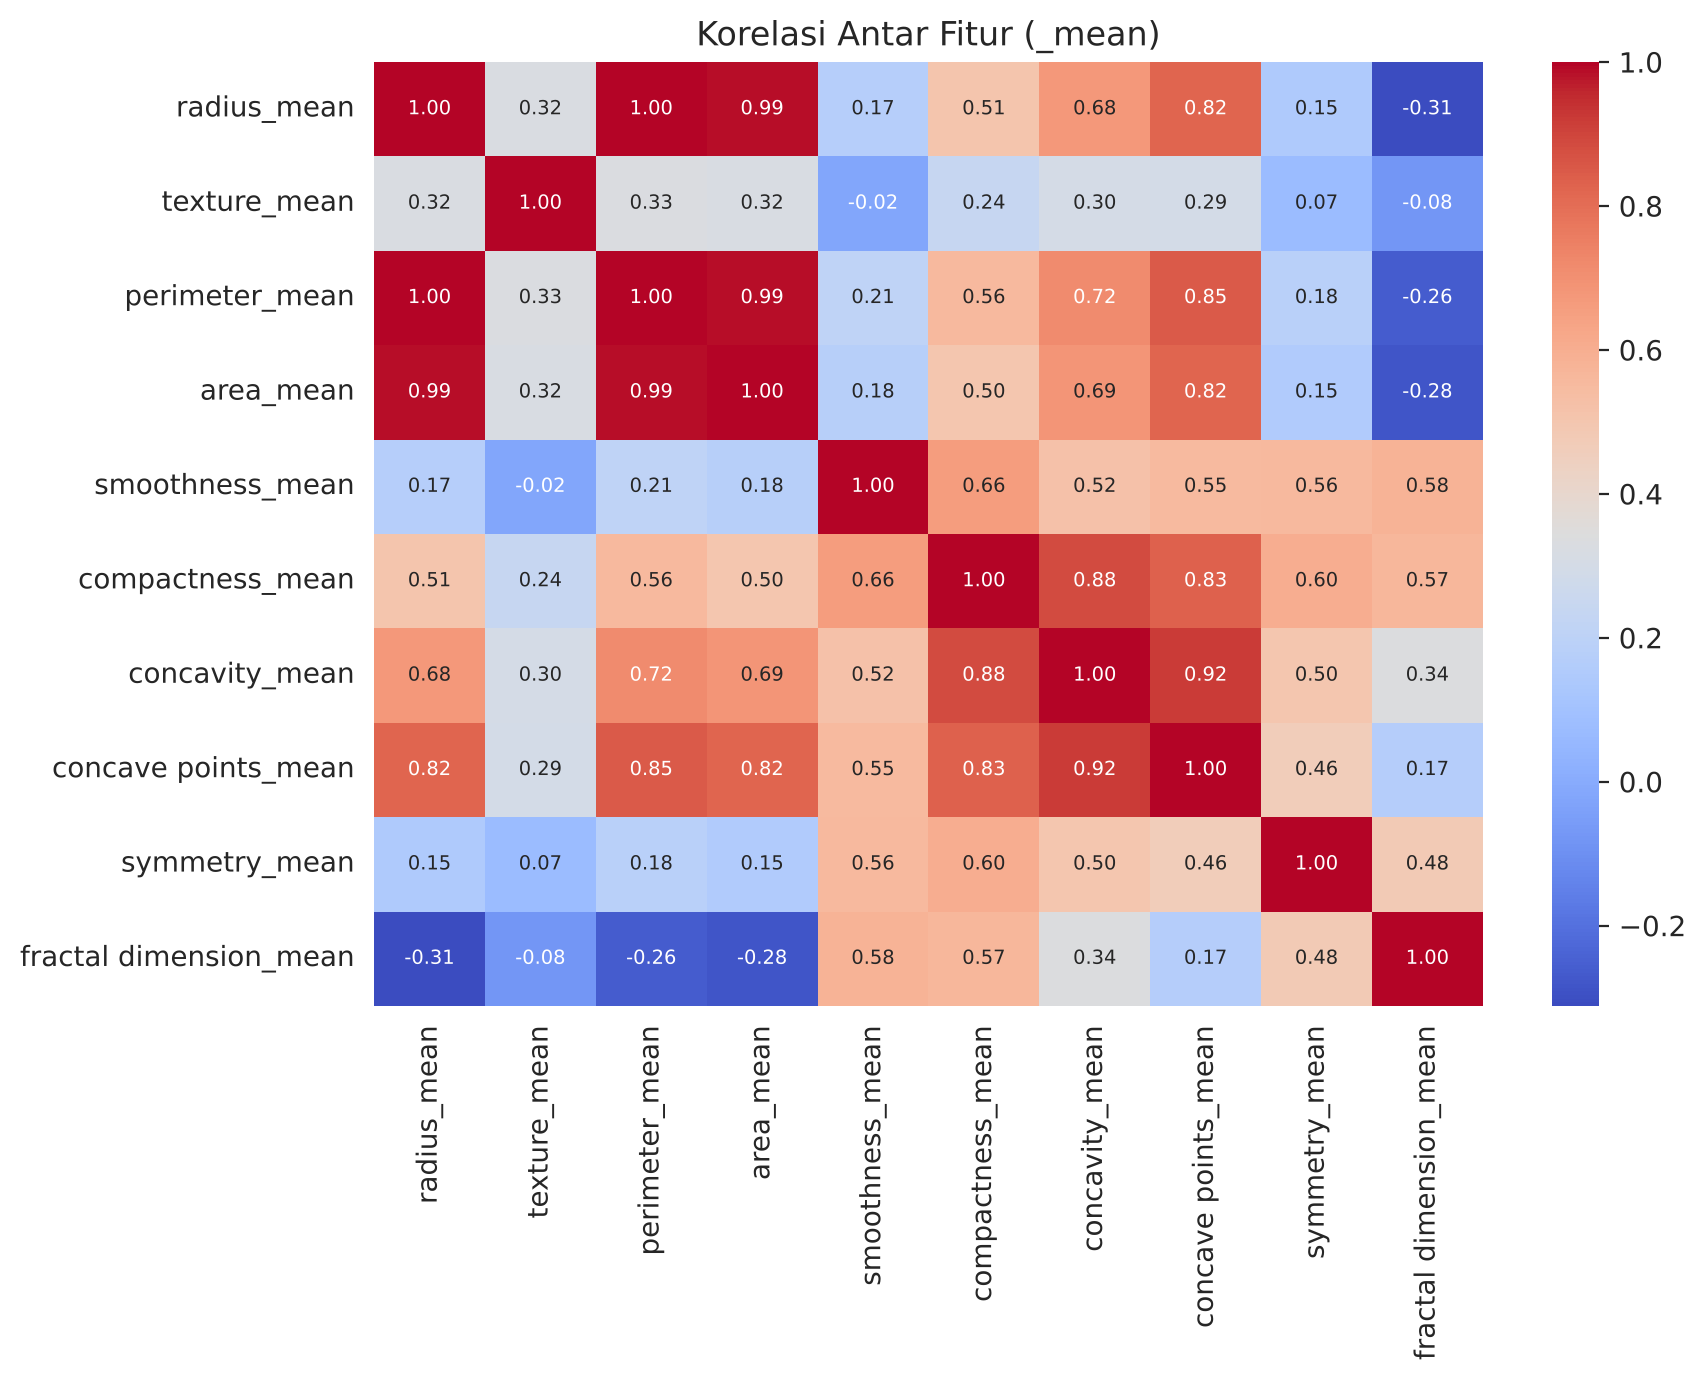

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Korelasi Antar Fitur (_mean)")
plt.tight_layout(); plt.savefig("../figures/03_korelasi.png", dpi=150); plt.show()

## 3. Preprocessing
- **Missing value**: dicek dan diisi median jika ada (pada dataset ini tidak ada).
- **Fitur kategorikal**: semua fitur numerik, hanya target yang kategorikal sehingga dikodekan dengan *Label Encoding* (M=1 ganas, B=0 jinak).

In [7]:
data = df[["diagnosis"] + features].copy()
for c in features:
    if data[c].isnull().any():
        data[c] = data[c].fillna(data[c].median())

data["diagnosis"] = data["diagnosis"].map({"B": 0, "M": 1})
X = data[features]
y = data["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("Latih:", X_train.shape, " Uji:", X_test.shape)

Latih: (398, 10)  Uji: (171, 10)


## 4. Model A (tanpa batasan) dan Model B (pruned)

In [8]:
model_a = DecisionTreeClassifier(max_depth=None, random_state=42)
model_a.fit(X_train, y_train)

model_b = DecisionTreeClassifier(max_depth=3, random_state=42)
model_b.fit(X_train, y_train)

print("Model A -> kedalaman:", model_a.get_depth(), "| jumlah daun:", model_a.get_n_leaves())
print("Model B -> kedalaman:", model_b.get_depth(), "| jumlah daun:", model_b.get_n_leaves())

Model A -> kedalaman: 7 | jumlah daun: 20
Model B -> kedalaman: 3 | jumlah daun: 8


## 5. Evaluasi dan Perbandingan

Model A (tanpa batas)
Confusion matrix:
 [[100   7]
 [  8  56]]
                 precision    recall  f1-score   support

Tumor Jinak (0)       0.93      0.93      0.93       107
Tumor Ganas (1)       0.89      0.88      0.88        64

       accuracy                           0.91       171
      macro avg       0.91      0.90      0.91       171
   weighted avg       0.91      0.91      0.91       171

Model B (max_depth=3)
Confusion matrix:
 [[101   6]
 [  6  58]]
                 precision    recall  f1-score   support

Tumor Jinak (0)       0.94      0.94      0.94       107
Tumor Ganas (1)       0.91      0.91      0.91        64

       accuracy                           0.93       171
      macro avg       0.93      0.93      0.93       171
   weighted avg       0.93      0.93      0.93       171



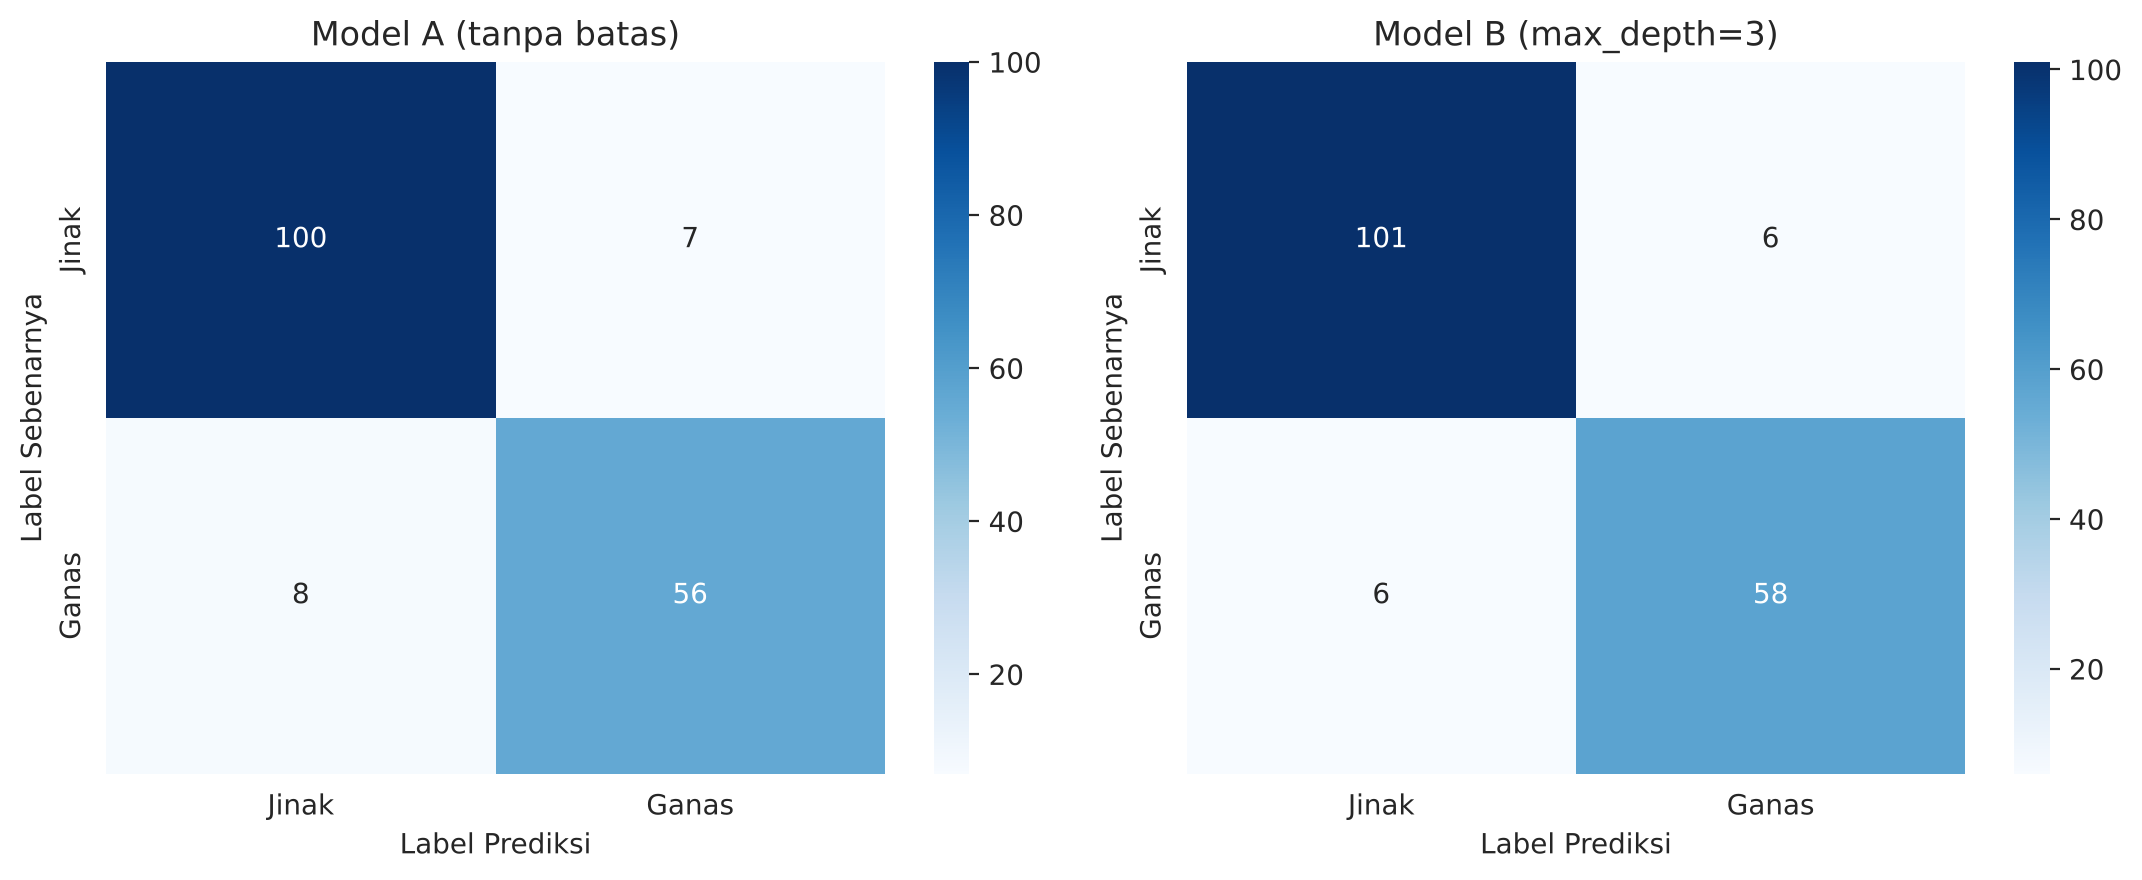

,train_acc,test_acc,auc,cv,recall_ganas,precision_ganas,depth,leaves
Model A (tanpa batas),1.0,0.912281,0.90479,0.912125,0.875,0.888889,7,20
Model B (max_depth=3),0.967337,0.929825,0.938303,0.917451,0.90625,0.90625,3,8


In [9]:
names = ["Tumor Jinak (0)", "Tumor Ganas (1)"]
results = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nm, m) in zip(axes, [("Model A (tanpa batas)", model_a), ("Model B (max_depth=3)", model_b)]):
    pred = m.predict(X_test)
    print("=" * 60); print(nm)
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=names))
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Jinak", "Ganas"], yticklabels=["Jinak", "Ganas"])
    ax.set_title(nm); ax.set_xlabel("Label Prediksi"); ax.set_ylabel("Label Sebenarnya")
    rep = classification_report(y_test, pred, output_dict=True)
    results[nm] = dict(
        train_acc=accuracy_score(y_train, m.predict(X_train)),
        test_acc=accuracy_score(y_test, pred),
        recall_ganas=rep["1"]["recall"], precision_ganas=rep["1"]["precision"],
        f1_ganas=rep["1"]["f1-score"],
        auc=roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
        cv=cross_val_score(m, X, y, cv=5).mean(),
        depth=int(m.get_depth()), leaves=int(m.get_n_leaves()),
        cm=cm.tolist())
plt.tight_layout(); plt.savefig("../figures/04_confusion_matrix.png", dpi=150); plt.show()
pd.DataFrame(results).T[["train_acc", "test_acc", "auc", "cv", "recall_ganas", "precision_ganas", "depth", "leaves"]].round(4)

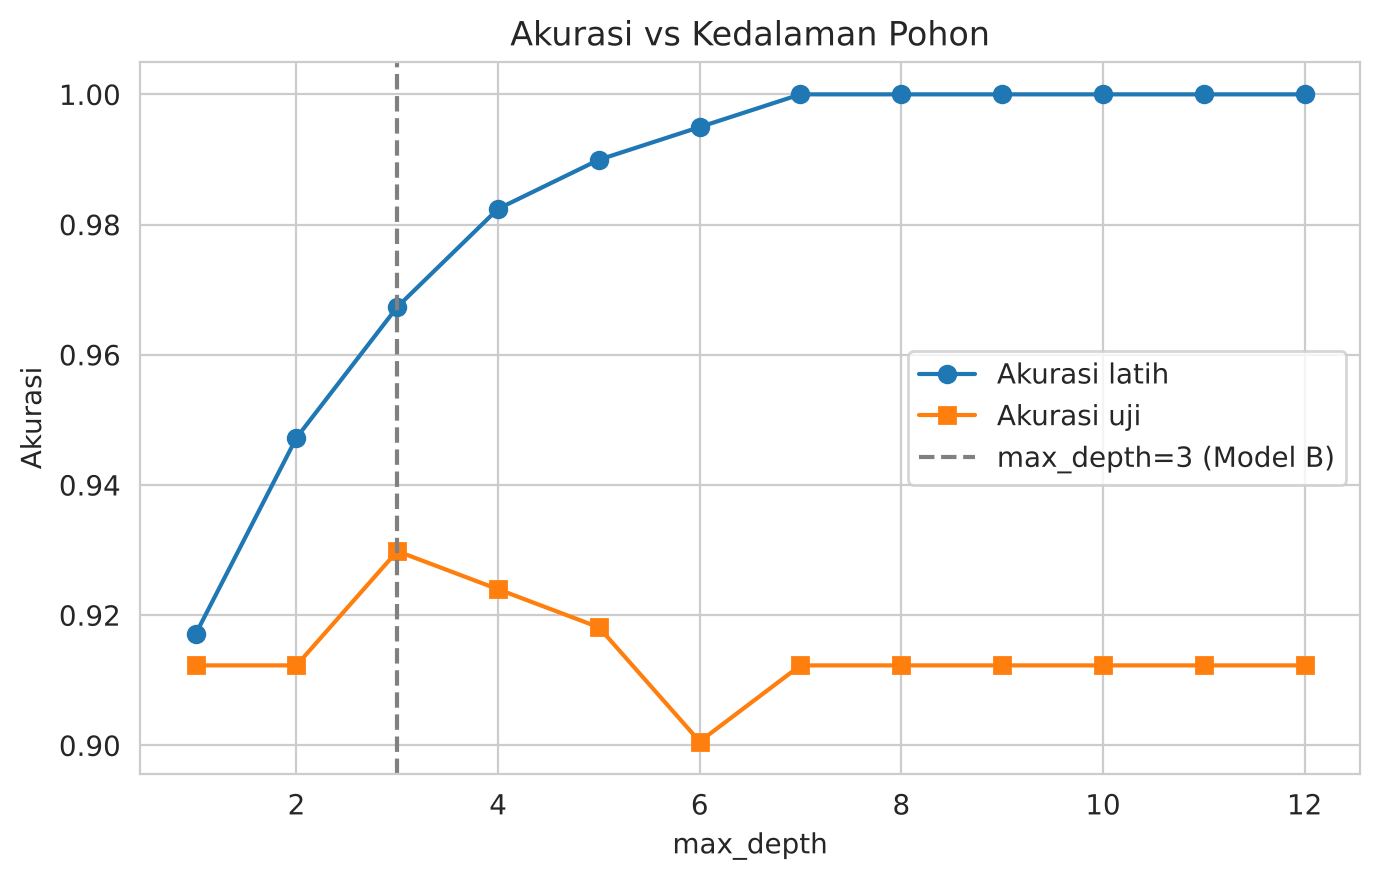

In [10]:
# Pengaruh max_depth terhadap overfitting
depths = list(range(1, 13))
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))
plt.figure(figsize=(7, 4.5))
plt.plot(depths, tr, "o-", label="Akurasi latih"); plt.plot(depths, te, "s-", label="Akurasi uji")
plt.axvline(3, color="gray", ls="--", label="max_depth=3 (Model B)")
plt.xlabel("max_depth"); plt.ylabel("Akurasi"); plt.title("Akurasi vs Kedalaman Pohon"); plt.legend()
plt.tight_layout(); plt.savefig("../figures/05_depth_curve.png", dpi=150); plt.show()

## 6. Visualisasi dan Interpretasi (Model B)

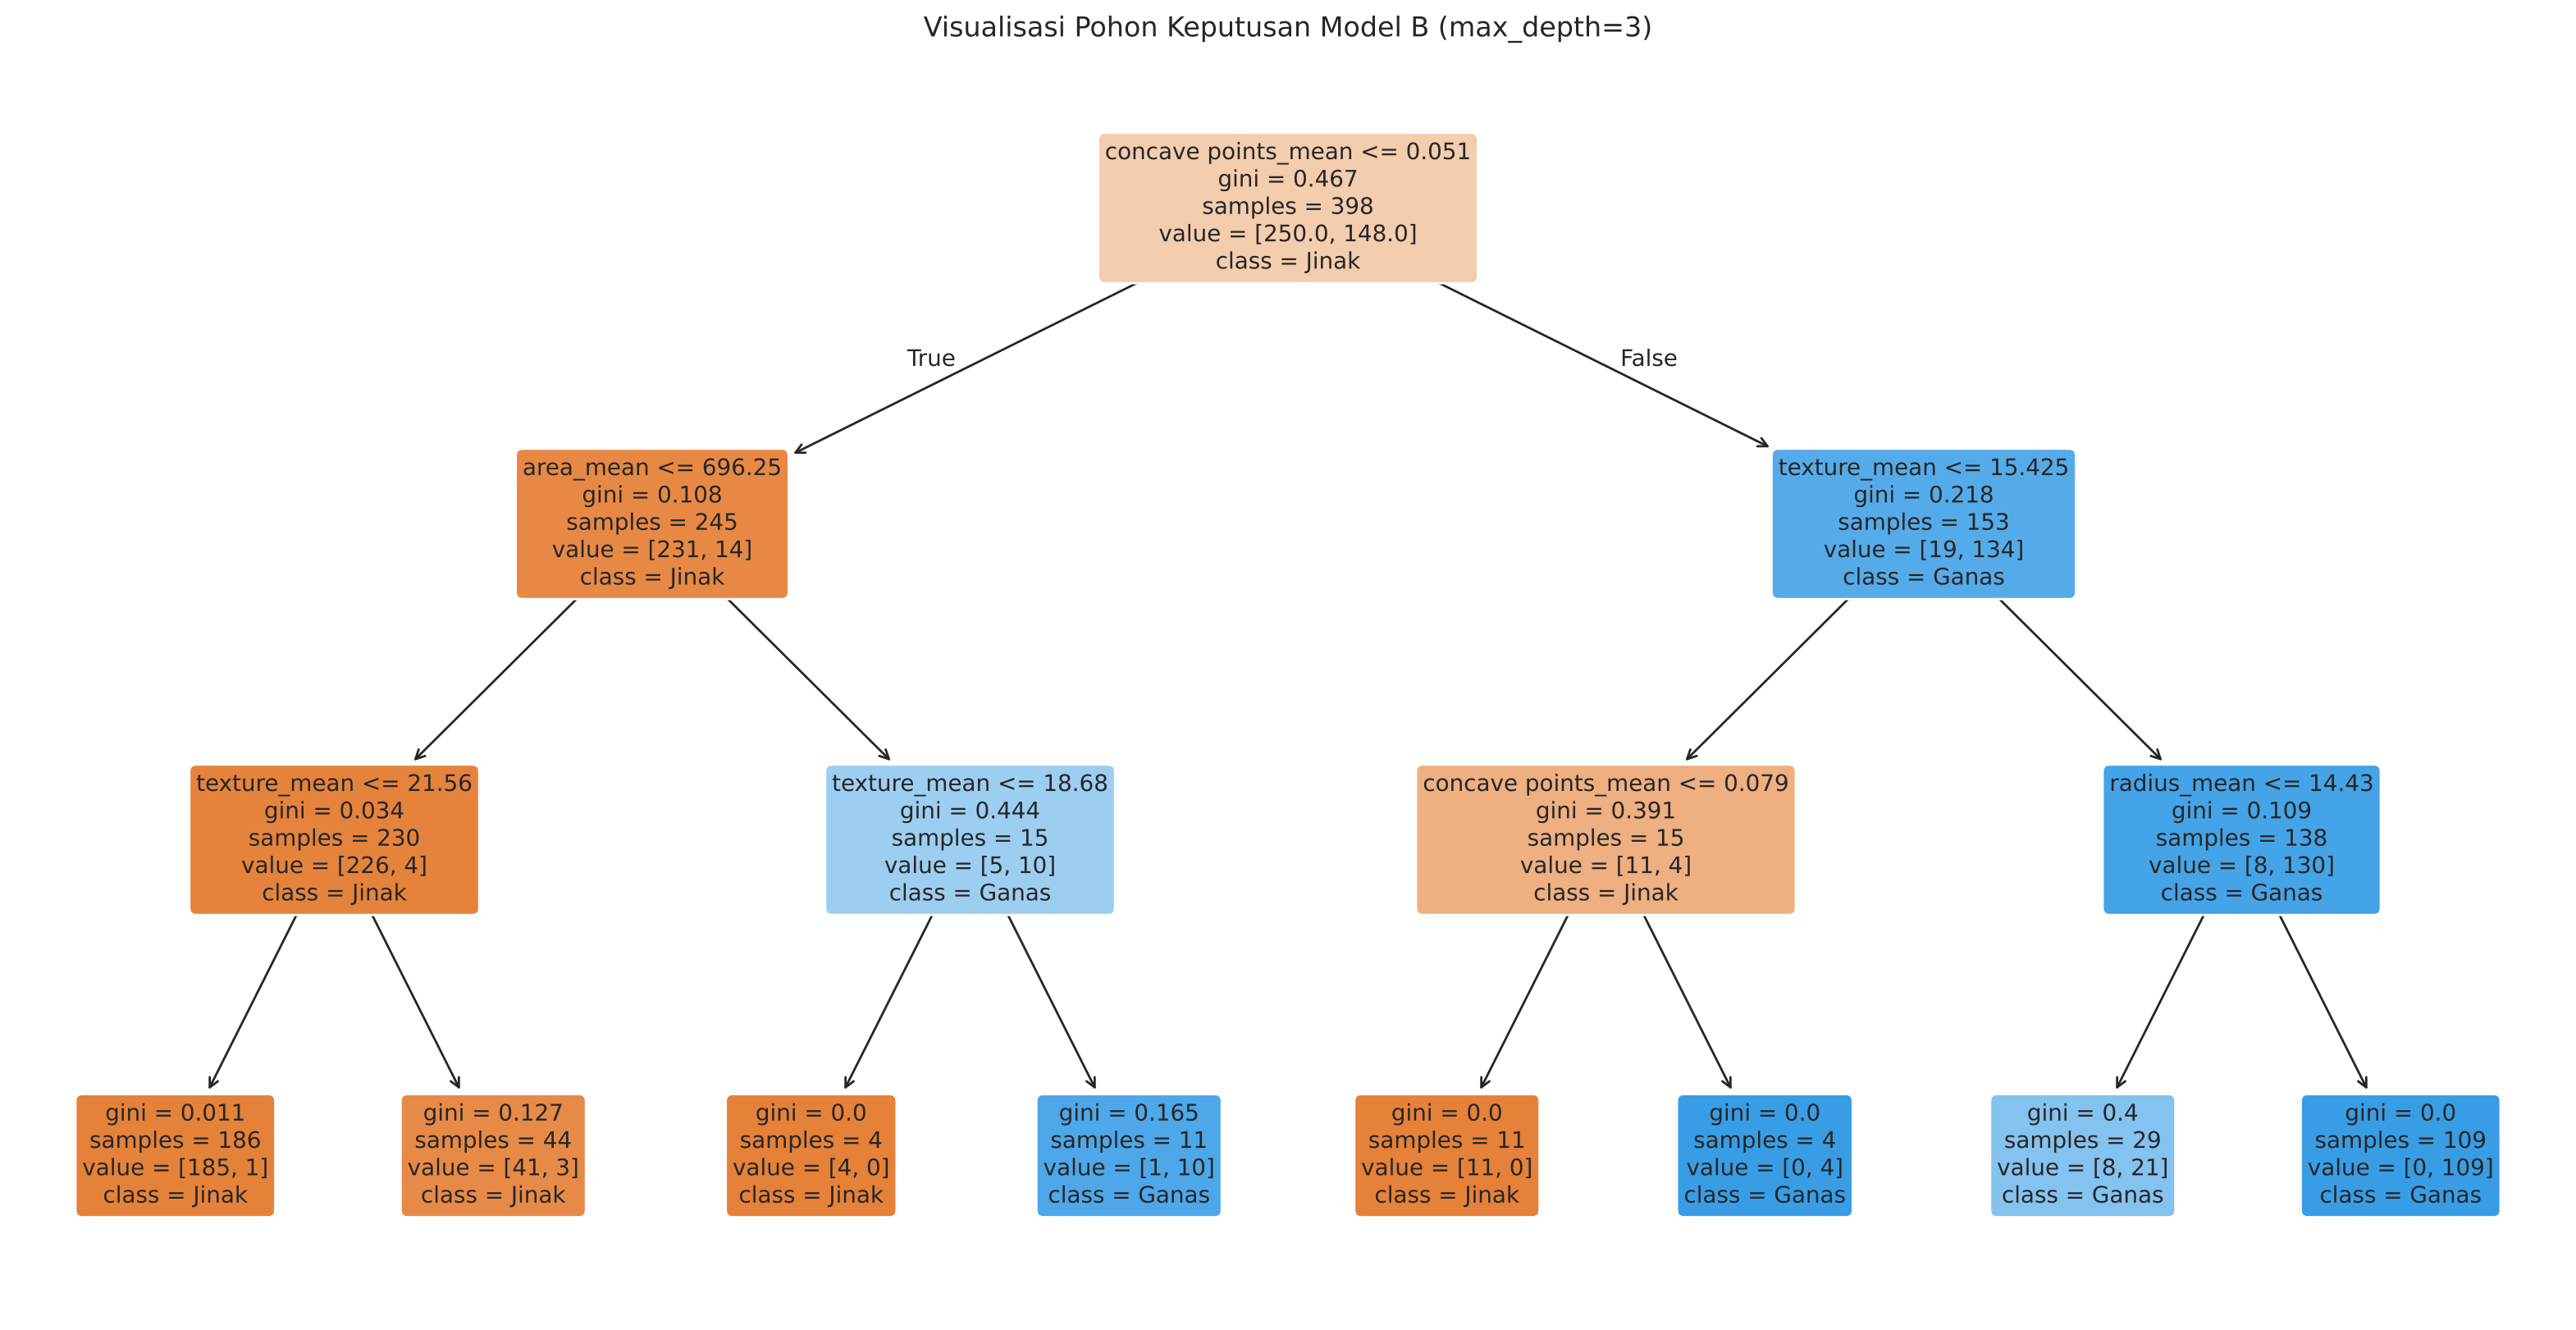

In [11]:
plt.figure(figsize=(20, 10))
plot_tree(model_b, feature_names=features, class_names=["Jinak", "Ganas"],
          filled=True, rounded=True, fontsize=10)
plt.title("Visualisasi Pohon Keputusan Model B (max_depth=3)")
plt.savefig("../figures/06_pohon_model_b.png", dpi=130, bbox_inches="tight"); plt.show()

In [12]:
rules = export_text(model_b, feature_names=features)
print(rules)
open("../figures/aturan_pohon.txt", "w").write(rules)

|--- concave points_mean <= 0.05
|   |--- area_mean <= 696.25
|   |   |--- texture_mean <= 21.56
|   |   |   |--- class: 0
|   |   |--- texture_mean >  21.56
|   |   |   |--- class: 0
|   |--- area_mean >  696.25
|   |   |--- texture_mean <= 18.68
|   |   |   |--- class: 0
|   |   |--- texture_mean >  18.68
|   |   |   |--- class: 1
|--- concave points_mean >  0.05
|   |--- texture_mean <= 15.43
|   |   |--- concave points_mean <= 0.08
|   |   |   |--- class: 0
|   |   |--- concave points_mean >  0.08
|   |   |   |--- class: 1
|   |--- texture_mean >  15.43
|   |   |--- radius_mean <= 14.43
|   |   |   |--- class: 1
|   |   |--- radius_mean >  14.43
|   |   |   |--- class: 1



684

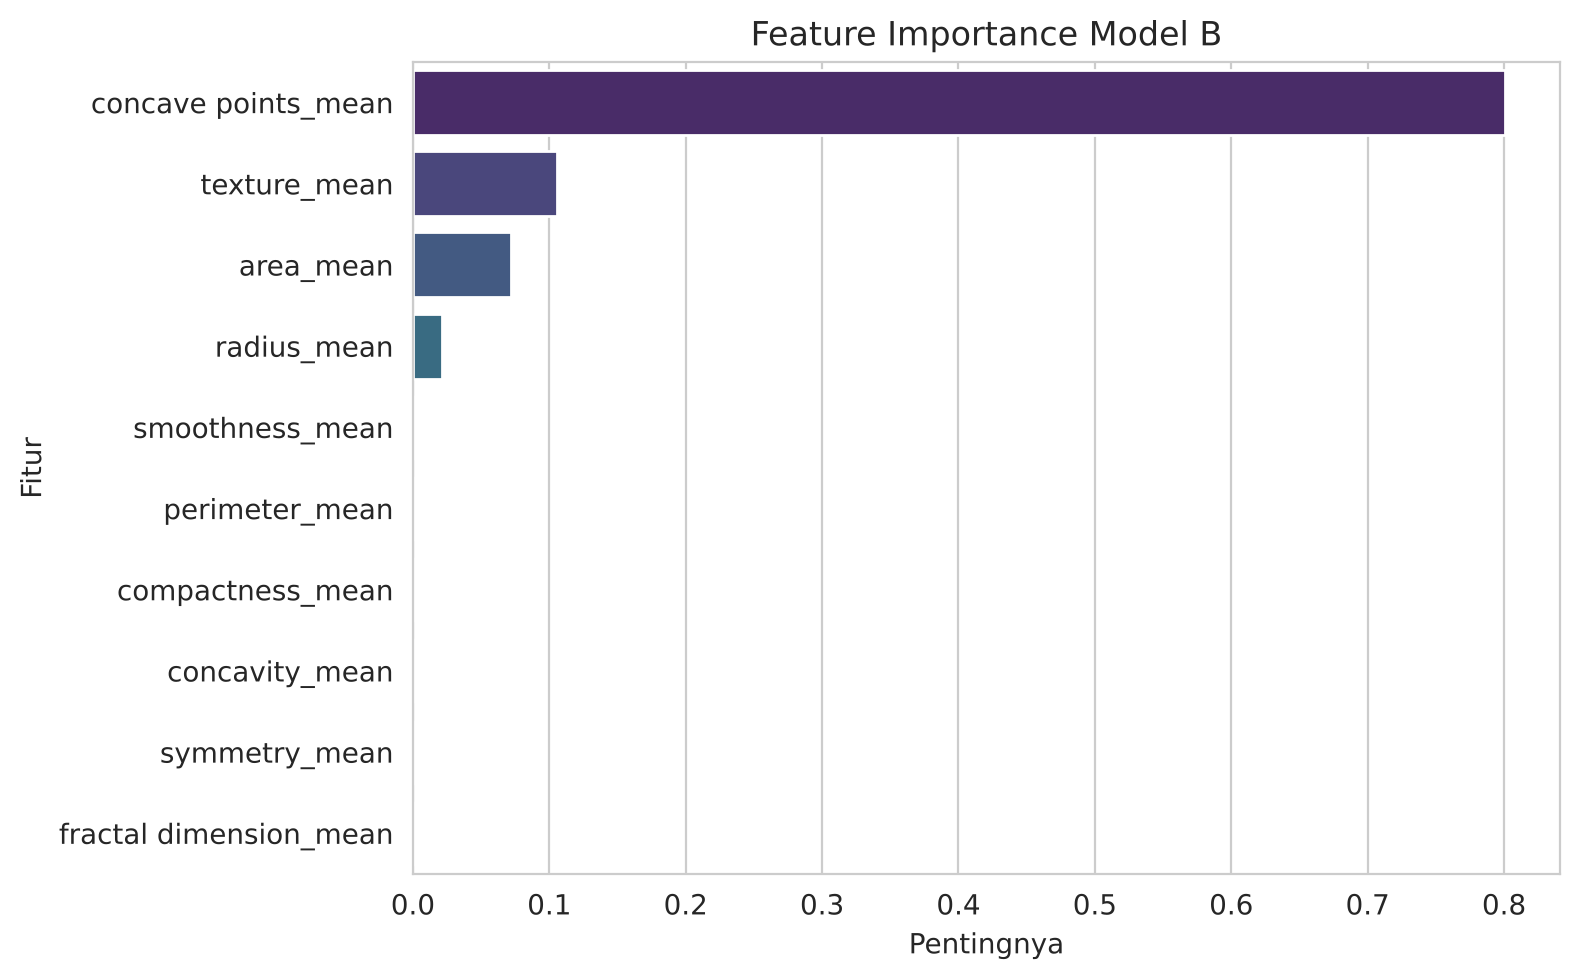

,Fitur,Pentingnya
7,concave points_mean,0.8010
1,texture_mean,0.1059
3,area_mean,0.0720
0,radius_mean,0.0211


In [13]:
imp = pd.DataFrame({"Fitur": features, "Pentingnya": model_b.feature_importances_}).sort_values("Pentingnya", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x="Pentingnya", y="Fitur", data=imp, hue="Fitur", palette="viridis", legend=False)
plt.title("Feature Importance Model B")
plt.tight_layout(); plt.savefig("../figures/07_feature_importance.png", dpi=150); plt.show()
imp[imp.Pentingnya > 0].round(4)

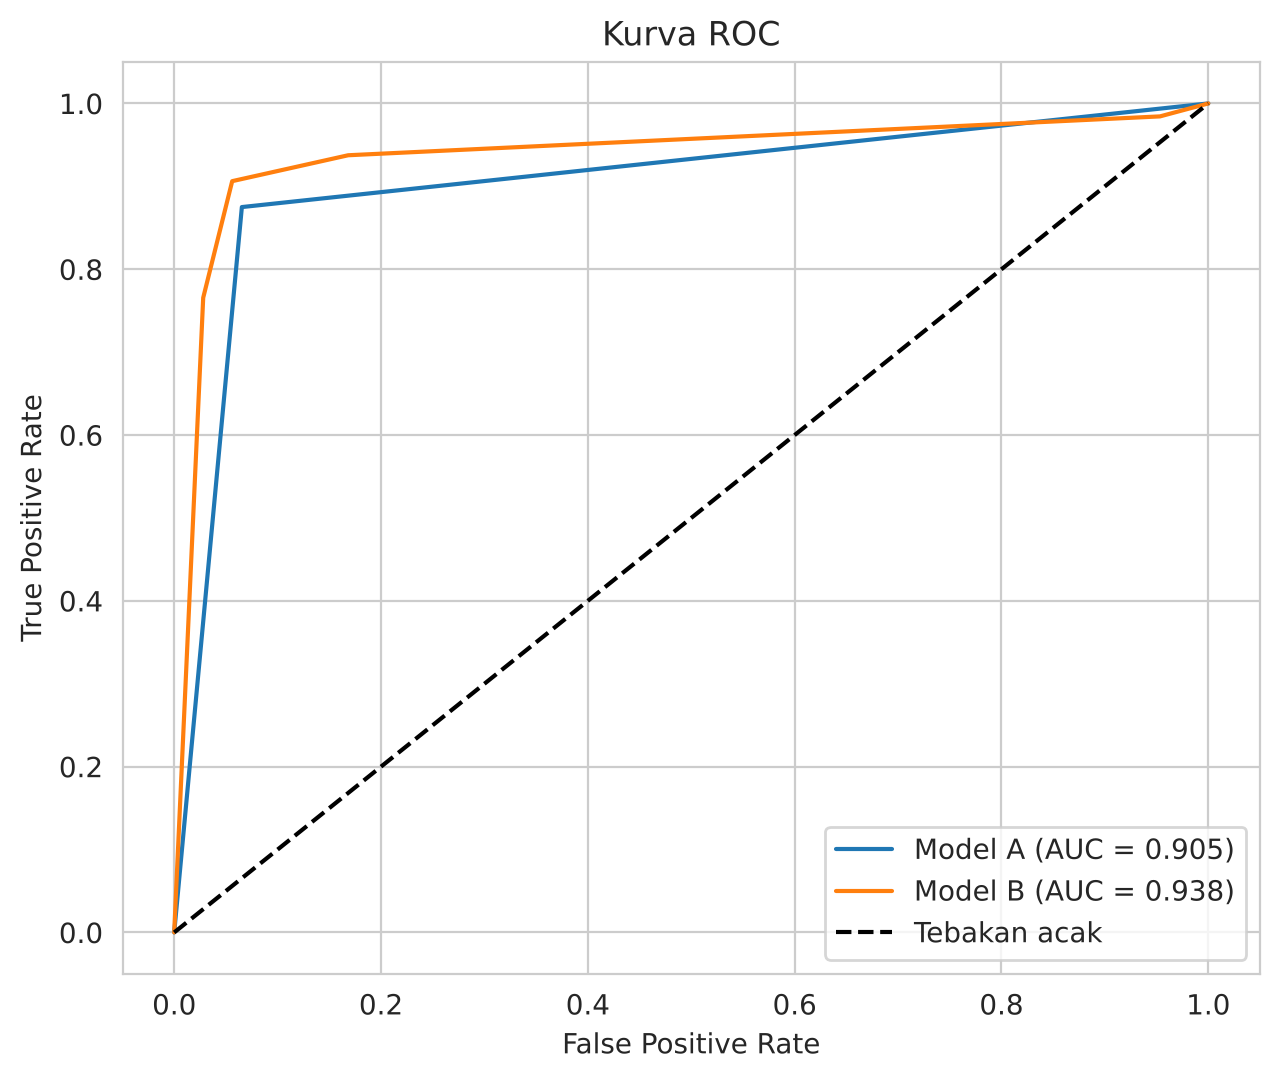

In [14]:
# Kurva ROC kedua model
plt.figure(figsize=(6.5, 5.5))
for nm, m in [("Model A", model_a), ("Model B", model_b)]:
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{nm} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Tebakan acak")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Kurva ROC"); plt.legend()
plt.tight_layout(); plt.savefig("../figures/08_roc.png", dpi=150); plt.show()

## 7. Simpan Model (Joblib)

In [15]:
joblib.dump(model_b, "../model/model_decision_tree.pkl")
joblib.dump(features, "../model/features.pkl")
results["imp"] = imp.round(4).to_dict("records")
results["n_train"] = len(X_train); results["n_test"] = len(X_test)
results["stats"] = {f: [float(X[f].min()), float(X[f].median()), float(X[f].max())] for f in features}
json.dump(results, open("../figures/hasil.json", "w"), indent=1, default=float)
print("Model tersimpan.")

Model tersimpan.


## 8. Kesimpulan
Model A (tanpa batas) mencapai akurasi latih 100% tetapi akurasi uji lebih rendah dari Model B, tanda overfitting. Model B (`max_depth=3`) lebih sederhana, mudah ditafsirkan, dan generalisasinya lebih baik, sehingga dipilih untuk aplikasi Flask.